# Credit Scoring & Financial Distress Prediction
**Complete Google Colab notebook | Agentic X internship project**

This notebook brings the project workflow into one place:
1. Load the Give Me Some Credit dataset
2. Explore and clean the data
3. Engineer features and split without leakage
4. Train Logistic Regression and Random Forest models
5. Evaluate classification and probability quality
6. Save the model and reports
7. Generate optional SHAP explanations

**Dataset required:** Upload the real Kaggle `cs-training.csv` when prompted, or place it in the suggested Google Drive location. This notebook does not contain the dataset.

**Responsible use:** Educational project only. This is not a validated lending decision system.

## 1. Install and import libraries

In [2]:
%pip -q install imbalanced-learn shap joblib

In [3]:
import os, json, warnings, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "SeriousDlqin2yrs"
print("Imports successful.")

Imports successful.


## 2. Load the dataset
Mount Drive and search common locations. If the CSV is not found, Colab will ask you to upload it.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

candidates = [
    "/content/drive/MyDrive/CreditScoring_project_files/data/raw/cs-training.csv",
    "/content/drive/MyDrive/CreditScoring_project_files/cs-training.csv",
    "/content/drive/MyDrive/cs-training.csv",
    "/content/cs-training.csv",
]
DATA_PATH = next((p for p in candidates if os.path.isfile(p)), None)

if DATA_PATH is None:
    from google.colab import files
    print("Upload the actual Kaggle cs-training.csv file:")
    uploaded = files.upload()
    csvs = [name for name in uploaded if name.lower().endswith(".csv")]
    if not csvs:
        raise FileNotFoundError("No CSV uploaded.")
    DATA_PATH = os.path.abspath(csvs[0])

df = pd.read_csv(DATA_PATH)
if df.empty:
    raise ValueError("CSV is empty. Replace any header-only placeholder with the actual Kaggle dataset.")
if TARGET not in df.columns:
    raise ValueError(f"Missing target column {TARGET!r}. Found: {df.columns.tolist()}")

unnamed = [c for c in df.columns if str(c).lower().startswith("unnamed:")]
if unnamed:
    df = df.drop(columns=unnamed)

print("Dataset:", DATA_PATH)
print("Shape:", df.shape)
display(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Upload the actual Kaggle cs-training.csv file:


Saving cs-training.csv to cs-training.csv
Dataset: /content/cs-training.csv
Shape: (150000, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 3. Exploratory data analysis

In [7]:
print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype"))
display(df.describe().T)
display(df.isna().sum().sort_values(ascending=False).head(20).to_frame("missing values"))
print("Duplicate rows:", df.duplicated().sum())

Shape: (150000, 11)


,dtype
SeriousDlqin2yrs,int64
RevolvingUtilizationOfUnsecuredLines,float64
age,int64
NumberOfTime30-59DaysPastDueNotWorse,int64
DebtRatio,float64
MonthlyIncome,float64
NumberOfOpenCreditLinesAndLoans,int64
NumberOfTimes90DaysLate,int64
NumberRealEstateLoansOrLines,int64
NumberOfTime60-89DaysPastDueNotWorse,int64


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


,missing values
MonthlyIncome,29731
NumberOfDependents,3924
SeriousDlqin2yrs,0
age,0
RevolvingUtilizationOfUnsecuredLines,0
DebtRatio,0
NumberOfTime30-59DaysPastDueNotWorse,0
NumberOfOpenCreditLinesAndLoans,0
NumberOfTimes90DaysLate,0
NumberRealEstateLoansOrLines,0


Duplicate rows: 609


,count,percentage
SeriousDlqin2yrs,,
0,139974,93.32
1,10026,6.68


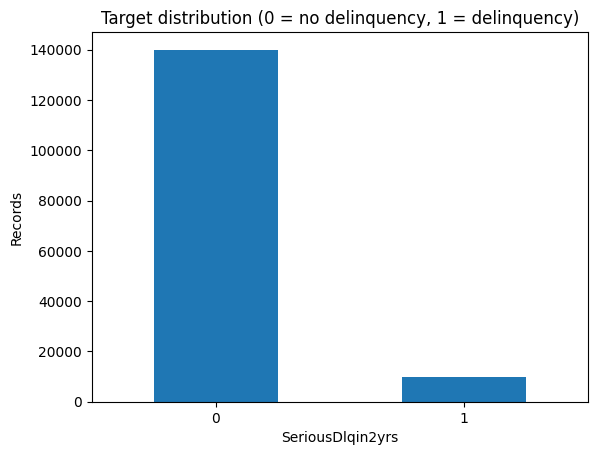

In [8]:
counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "percentage": (counts / len(df) * 100).round(2)}))
counts.plot(kind="bar", rot=0, title="Target distribution (0 = no delinquency, 1 = delinquency)")
plt.ylabel("Records")
plt.show()

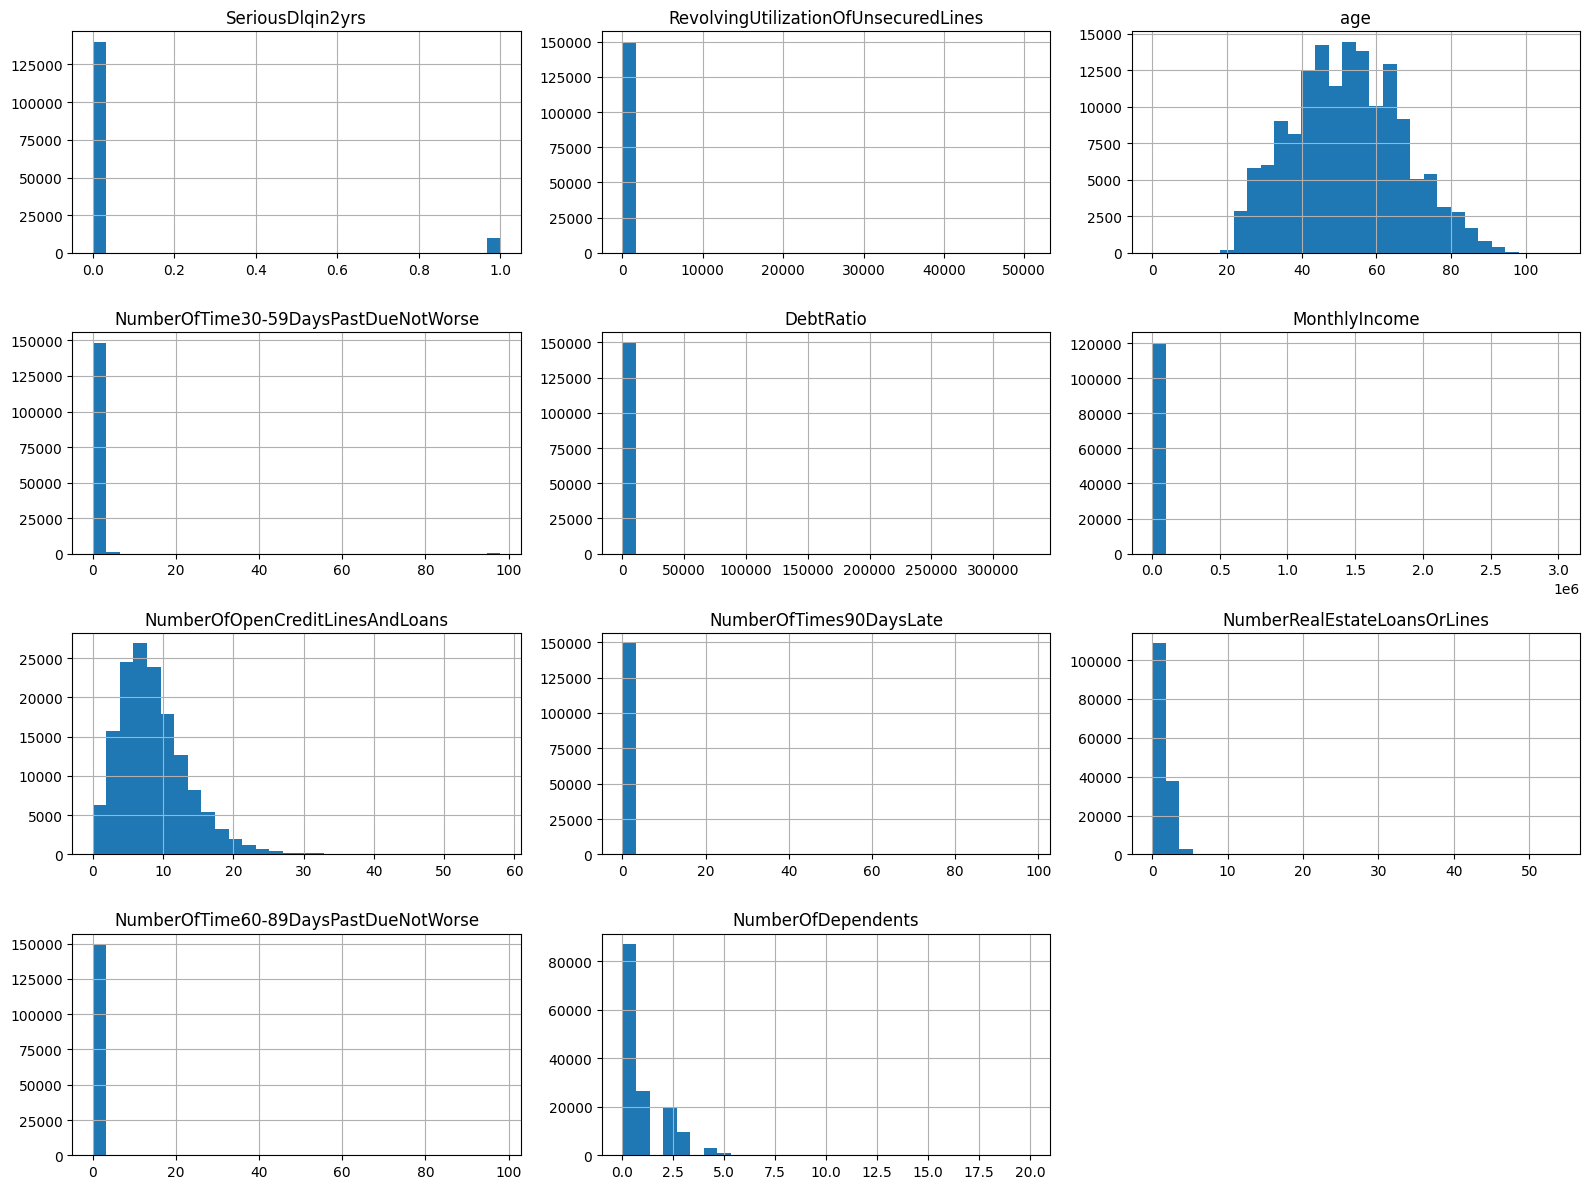

In [9]:
num_cols = df.select_dtypes(include=np.number).columns
df[num_cols].hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

,correlation with target
NumberOfTime30-59DaysPastDueNotWorse,0.125587
NumberOfTimes90DaysLate,0.117175
age,-0.115386
NumberOfTime60-89DaysPastDueNotWorse,0.102261
NumberOfDependents,0.046048
NumberOfOpenCreditLinesAndLoans,-0.029669
MonthlyIncome,-0.019746
DebtRatio,-0.007602
NumberRealEstateLoansOrLines,-0.007038
RevolvingUtilizationOfUnsecuredLines,-0.001802


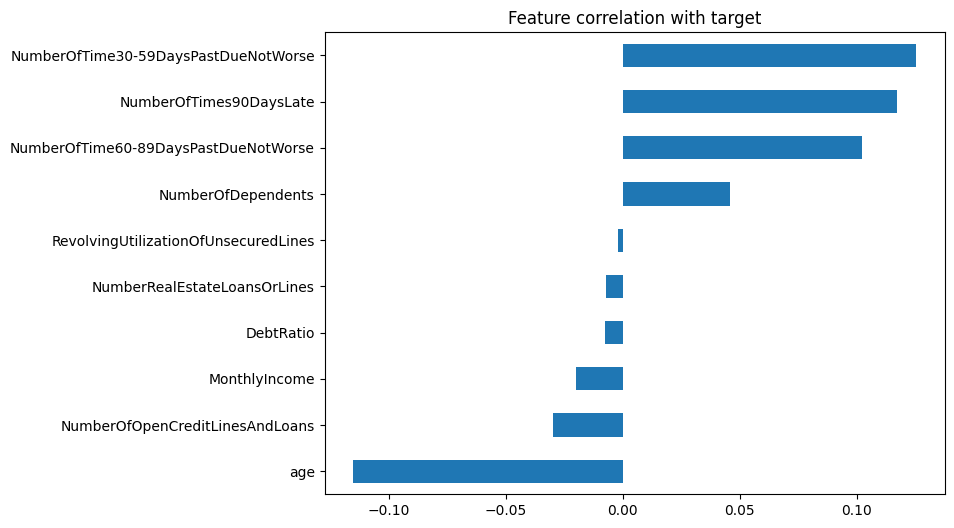

In [10]:
corr = df.select_dtypes(include=np.number).corr(numeric_only=True)
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
display(target_corr.to_frame("correlation with target"))
target_corr.sort_values().plot(kind="barh", figsize=(8, 6), title="Feature correlation with target")
plt.show()

## 4. Feature engineering and split

Deterministic feature engineering is performed before splitting. Learned preprocessing (imputation/scaling) is fitted only inside the training pipeline. SMOTE, if enabled, is also confined to training.

In [11]:
data = df.copy()

# Remove an exact duplicate alias only when it is truly identical.
if ("RevolvingUtilizationRatio" in data.columns
    and "RevolvingUtilizationOfUnsecuredLines" in data.columns
    and data["RevolvingUtilizationRatio"].equals(data["RevolvingUtilizationOfUnsecuredLines"])):
    data = data.drop(columns=["RevolvingUtilizationRatio"])

if {"MonthlyIncome", "DebtRatio"}.issubset(data.columns):
    data["EstimatedMonthlyDebt"] = data["MonthlyIncome"] * data["DebtRatio"]

late_cols = [c for c in [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
] if c in data.columns]
if late_cols:
    data["TotalPastDueEvents"] = data[late_cols].fillna(0).sum(axis=1)

data = data.dropna(subset=[TARGET])
y = data[TARGET].astype(int)
X = data.drop(columns=[TARGET])

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("Target must contain binary values 0 and 1.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Target rate:", round(y.mean(), 4))

Train: (120000, 12) Test: (30000, 12)
Target rate: 0.0668


In [14]:
numeric_features = X_train.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
transformers = [("numeric", numeric_pipe, numeric_features)]

if categorical_features:
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ])
    transformers.append(("categorical", categorical_pipe, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 12
Categorical features: 0


## 5. Train models
Logistic Regression is the class-weighted baseline. Random Forest optionally uses SMOTE inside an imbalanced-learn pipeline. The test set is never resampled.

In [16]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

USE_SMOTE = True

logistic = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE))
])

rf_steps = [("preprocessor", preprocessor)]
if USE_SMOTE:
    rf_steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
rf_steps.append(("model", RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight=None if USE_SMOTE else "balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1
)))
random_forest = ImbPipeline(steps=rf_steps)

models = {"Logistic Regression": logistic, "Random Forest": random_forest}
fitted_models = {}
for name, model in models.items():
    print("Training", name)
    model.fit(X_train, y_train)
    fitted_models[name] = model

print("Training complete.")

Training Logistic Regression
Training Random Forest
Training complete.


## 6. Evaluate models
Metrics are calculated on the held-out test set using a 0.50 threshold. This threshold is illustrative, not necessarily optimal.

In [17]:
results = []
probabilities_by_model = {}

for name, model in fitted_models.items():
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.50).astype(int)
    probabilities_by_model[name] = probs
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probs),
        "pr_auc": average_precision_score(y_test, probs),
        "brier_score": brier_score_loss(y_test, probs)
    })

results_df = pd.DataFrame(results).set_index("model").sort_values("pr_auc", ascending=False)
display(results_df.round(4))

,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score
model,,,,,,,
Logistic Regression,0.7765,0.1811,0.6658,0.2848,0.8064,0.3245,0.1785
Random Forest,0.9167,0.3714,0.3556,0.3633,0.8337,0.3134,0.0681


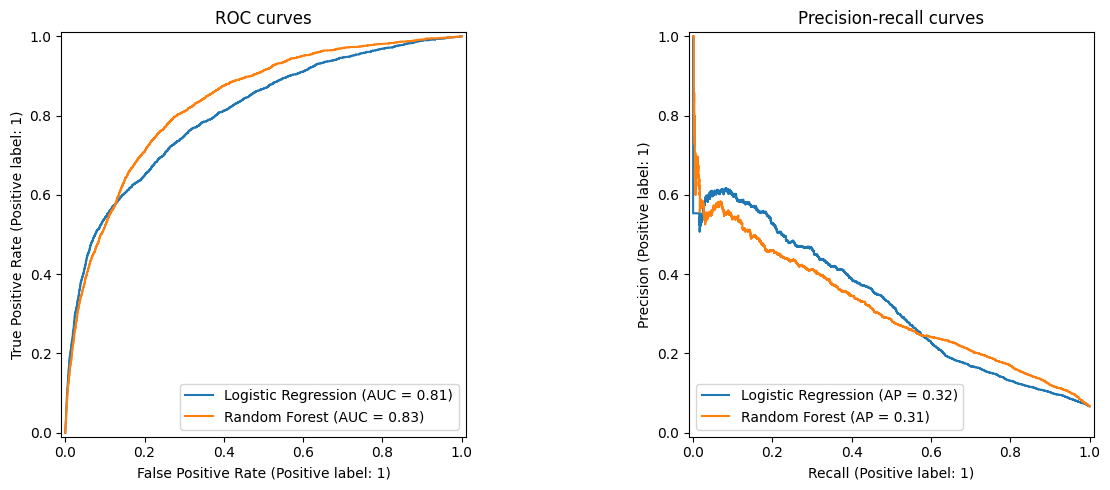

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, probs in probabilities_by_model.items():
    RocCurveDisplay.from_predictions(y_test, probs, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, probs, name=name, ax=axes[1])
axes[0].set_title("ROC curves")
axes[1].set_title("Precision-recall curves")
plt.tight_layout()
plt.show()

Top model by test PR-AUC (exploratory): Logistic Regression
              precision    recall  f1-score   support

           0       0.97      0.78      0.87     27995
           1       0.18      0.67      0.28      2005

    accuracy                           0.78     30000
   macro avg       0.58      0.73      0.58     30000
weighted avg       0.92      0.78      0.83     30000



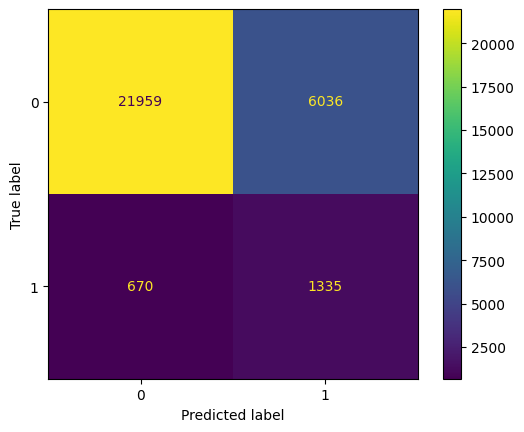

In [19]:
# Exploratory selection by test PR-AUC. For rigorous model selection, tune on a validation
# split and use the test set only once for final reporting.
best_name = results_df.index[0]
best_model = fitted_models[best_name]
best_probs = probabilities_by_model[best_name]
best_preds = (best_probs >= 0.50).astype(int)

print("Top model by test PR-AUC (exploratory):", best_name)
print(classification_report(y_test, best_preds, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_preds)
plt.show()

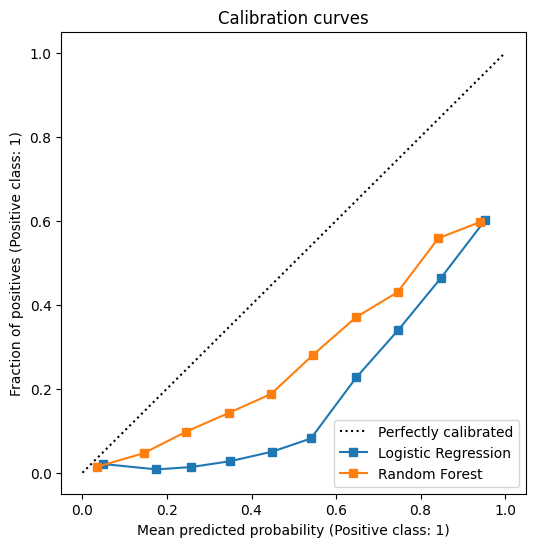

In [20]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, probs in probabilities_by_model.items():
    CalibrationDisplay.from_predictions(y_test, probs, n_bins=10, name=name, ax=ax)
ax.set_title("Calibration curves")
plt.show()

## 7. Threshold analysis
This is a descriptive comparison. In a formal workflow, select the threshold on validation data using documented error costs.

In [21]:
threshold_rows = []
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    pred = (best_probs >= threshold).astype(int)
    threshold_rows.append({
        "threshold": threshold,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0)
    })
display(pd.DataFrame(threshold_rows).round(4))

,threshold,precision,recall,f1
0,0.1,0.0669,0.9995,0.1254
1,0.2,0.0698,0.9940,0.1304
2,0.3,0.0858,0.9516,0.1574
3,0.4,0.1159,0.8484,0.2040
4,0.5,0.1811,0.6658,0.2848
5,0.6,0.3362,0.4833,0.3966
6,0.7,0.4360,0.3277,0.3741


## 8. Save model and reports

In [22]:
OUTPUT_DIR = Path("/content/credit_scoring_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

model_path = OUTPUT_DIR / "credit_scoring_pipeline.joblib"
joblib.dump(best_model, model_path)
results_df.to_csv(OUTPUT_DIR / "model_results.csv")

metadata = {
    "selected_model": best_name,
    "target": TARGET,
    "random_state": RANDOM_STATE,
    "test_size": 0.20,
    "threshold_used_for_report": 0.50,
    "features": X.columns.tolist(),
    "smote_enabled_for_random_forest": USE_SMOTE,
    "warning": "Educational model; not validated for lending decisions."
}
with open(OUTPUT_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model and reports to", OUTPUT_DIR)

Saved model and reports to /content/credit_scoring_outputs


## 9. Example prediction using one held-out record

In [23]:
example = X_test.iloc[[0]]
prob = float(best_model.predict_proba(example)[0, 1])
print(f"Predicted probability of serious delinquency: {prob:.2%}")
print("Illustrative band:", "Higher predicted risk" if prob >= 0.50 else "Lower predicted risk")
display(example)

Predicted probability of serious delinquency: 27.58%
Illustrative band: Lower predicted risk


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,EstimatedMonthlyDebt,TotalPastDueEvents
10682,0.019252,66,0,0.433926,5175.0,13,0,1,0,0.0,2245.566072,0


## 10. SHAP explainability (optional)
SHAP values explain model associations, not causes. This section samples at most 100 test rows to limit runtime.

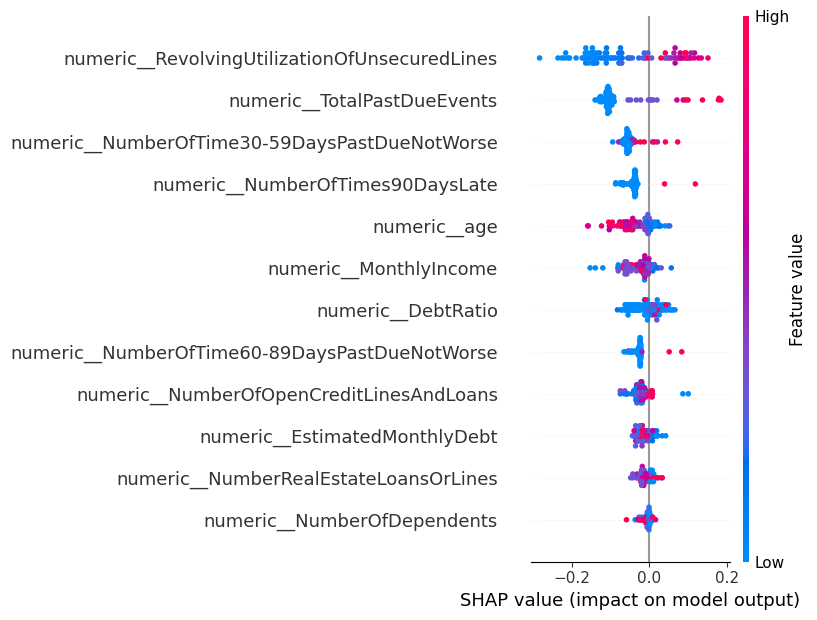

In [24]:
try:
    import shap
    if "Random Forest" not in fitted_models:
        raise RuntimeError("Random Forest model not available.")

    rf = fitted_models["Random Forest"]
    prep = rf.named_steps["preprocessor"]
    estimator = rf.named_steps["model"]
    sample_raw = X_test.sample(min(100, len(X_test)), random_state=RANDOM_STATE)
    sample_transformed = prep.transform(sample_raw)
    names = prep.get_feature_names_out()

    explainer = shap.TreeExplainer(estimator)
    shap_values = explainer.shap_values(sample_transformed)
    positive_values = shap_values[1] if isinstance(shap_values, list) else shap_values
    if getattr(positive_values, "ndim", 0) == 3:
        positive_values = positive_values[:, :, 1]

    shap.summary_plot(positive_values, sample_transformed, feature_names=names)
except Exception as exc:
    print("SHAP could not run in this session:", repr(exc))
    print("The training and evaluation results above are still available.")

## 11. Copy outputs to Google Drive

In [25]:
drive_output = Path("/content/drive/MyDrive/CreditScoring_outputs")
drive_output.mkdir(parents=True, exist_ok=True)
for file in OUTPUT_DIR.iterdir():
    if file.is_file():
        shutil.copy2(file, drive_output / file.name)
print("Outputs copied to:", drive_output)

Outputs copied to: /content/drive/MyDrive/CreditScoring_outputs
